In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error,r2_score
from sklearn.preprocessing import StandardScaler

In [5]:
from sklearn.datasets import fetch_california_housing
housing=fetch_california_housing()
print(housing.data)
df=pd.DataFrame(housing.data,columns=housing.feature_names)
df['MedHouseVal']=housing.target
print(df.head())
print(df.isnull().sum())

[[   8.3252       41.            6.98412698 ...    2.55555556
    37.88       -122.23      ]
 [   8.3014       21.            6.23813708 ...    2.10984183
    37.86       -122.22      ]
 [   7.2574       52.            8.28813559 ...    2.80225989
    37.85       -122.24      ]
 ...
 [   1.7          17.            5.20554273 ...    2.3256351
    39.43       -121.22      ]
 [   1.8672       18.            5.32951289 ...    2.12320917
    39.43       -121.32      ]
 [   2.3886       16.            5.25471698 ...    2.61698113
    39.37       -121.24      ]]
   MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  \
0  8.3252      41.0  6.984127   1.023810       322.0  2.555556     37.88   
1  8.3014      21.0  6.238137   0.971880      2401.0  2.109842     37.86   
2  7.2574      52.0  8.288136   1.073446       496.0  2.802260     37.85   
3  5.6431      52.0  5.817352   1.073059       558.0  2.547945     37.85   
4  3.8462      52.0  6.281853   1.081081       565.0  2.1

In [17]:
x=df[['AveRooms']]
y=df['MedHouseVal']
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)
print(f"Training data shape:{x_train.shape}")
print(f"Testing data shape:{x_test.shape}")

Training data shape:(16512, 1)
Testing data shape:(4128, 1)


In [29]:
scalar=StandardScaler()
scalar.fit(x_train)
x_train_scaled=scalar.transform(x_train)
x_test_scaled=scalar.transform(x_test)
print("Mean/std used for scaling:",scalar.mean_,scalar.scale_)

Mean/std used for scaling: [5.43523502] [2.38730258]


In [30]:
model=LinearRegression()
model.fit(x_train_scaled,y_train)
print(f"Intercept:{model.intercept_}")
print(f"Slope:{model.coef_}")

Intercept:2.071946937378876
Slope:[0.18323882]


In [31]:
y_pred=model.predict(x_test_scaled)
predictions=pd.DataFrame({'Actual':y_test,'Predicted':y_pred})
print(predictions.head())

        Actual  Predicted
20046  0.47700   1.976537
3024   0.45800   2.041563
15663  5.00001   1.960031
20484  2.18600   2.127856
9814   2.78000   2.076380


In [32]:
mse=mean_squared_error(y_test,y_pred)
print(f"Mean square error:{mse}")
r2=r2_score(y_test,y_pred)
print(f"R-squared error:{r2}")

Mean square error:1.29233144408073
R-squared error:0.01379533753228468


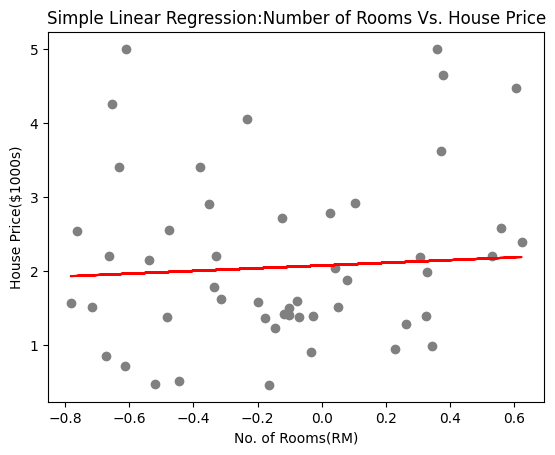

In [33]:
plt.scatter(x_test_scaled[:50],y_test[:50],color='gray')
plt.plot(x_test_scaled[:50],y_pred[:50],color='red')
plt.xlabel('No. of Rooms(RM)')
plt.ylabel('House Price($1000s)')
plt.title('Simple Linear Regression:Number of Rooms Vs. House Price')
plt.show()

Text(0.5, 1.0, 'Residual Distribution')

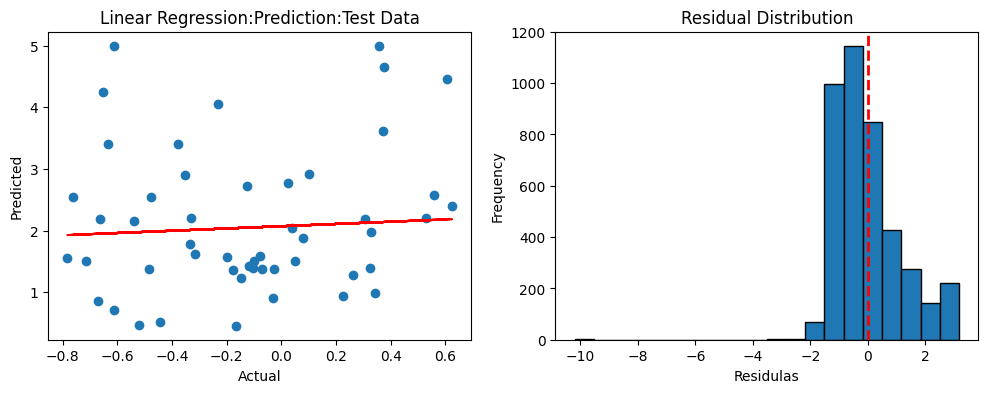

In [34]:
fig,axes=plt.subplots(1,2,figsize=(12,4))
axes[0].scatter(x_test_scaled[:50],y_test[:50])
axes[0].plot(x_test_scaled[:50],y_pred[:50],color='red',label='Regression')
axes[0].set_xlabel('Actual')
axes[0].set_ylabel('Predicted')
axes[0].set_title('Linear Regression:Prediction:Test Data')
residuals=y_test-y_pred
axes[1].hist(residuals,bins=20,edgecolor='black')
axes[1].axvline(x=0,color='red',linestyle='dashed',linewidth=2)
axes[1].set_xlabel('Residulas')
axes[1].set_ylabel('Frequency')
axes[1].set_title('Residual Distribution')
